In [1]:
%pip install pandas numpy matplotlib scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd 
data = pd.read_csv('uber.csv') 
print(data.head()) 
print(data.info()) 
print(data.isnull().sum()) 

   Unnamed: 0                            key  fare_amount  ... dropoff_longitude  dropoff_latitude  passenger_count
0    24238194    2015-05-07 19:52:06.0000003          7.5  ...        -73.999512         40.723217                1
1    27835199    2009-07-17 20:04:56.0000002          7.7  ...        -73.994710         40.750325                1
2    44984355   2009-08-24 21:45:00.00000061         12.9  ...        -73.962565         40.772647                1
3    25894730    2009-06-26 08:22:21.0000001          5.3  ...        -73.965316         40.803349                3
4    17610152  2014-08-28 17:47:00.000000188         16.0  ...        -73.973082         40.761247                5

[5 rows x 9 columns]
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-n

In [6]:
data = data.dropna() 
data = data[data['fare_amount'] > 0] 
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime']) 
data['hour'] = data['pickup_datetime'].dt.hour 
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek 

In [10]:
import numpy as np

# Coordonnées GPS du départ et de l'arrivée
lat1 = np.radians(data['pickup_latitude'])
lat2 = np.radians(data['dropoff_latitude'])
lon1 = np.radians(data['pickup_longitude'])
lon2 = np.radians(data['dropoff_longitude'])

# Différences entre les coordonnées
dlat = lat2 - lat1
dlon = lon2 - lon1

# Formule de Haversine
a = (
    np.sin(dlat / 2)**2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2)**2
)

data['distance'] = 6371 * 2 * np.arcsin(
    np.sqrt(np.clip(a, 0, 1))
)

print(data[['distance', 'fare_amount']].head())

   distance  fare_amount
0  1.683323          7.5
1  2.457590          7.7
2  5.036377         12.9
3  1.661683          5.3
4  4.475450         16.0


In [11]:
from sklearn.model_selection import train_test_split 
 
X = data[['distance', 'hour', 'day_of_week']] 
y = data['fare_amount'] 
 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) 

In [12]:
from sklearn.linear_model import LinearRegression 
 
lr = LinearRegression() 
lr.fit(X_train, y_train) 
y_pred = lr.predict(X_test) 

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
import numpy as np 
 
mae = mean_absolute_error(y_test, y_pred) 
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) 
r2 = r2_score(y_test, y_pred) 
 
print('MAE =', mae) 
print('RMSE =', rmse) 
print('R² =', r2) 

MAE = 6.024606980536917
RMSE = 9.635978518193681
R² = 0.0014590917488974675


In [16]:
from sklearn.ensemble import RandomForestRegressor 
 
rf = RandomForestRegressor(n_estimators=100, random_state=42) 
rf.fit(X_train, y_train) 
y_pred_rf = rf.predict(X_test) 

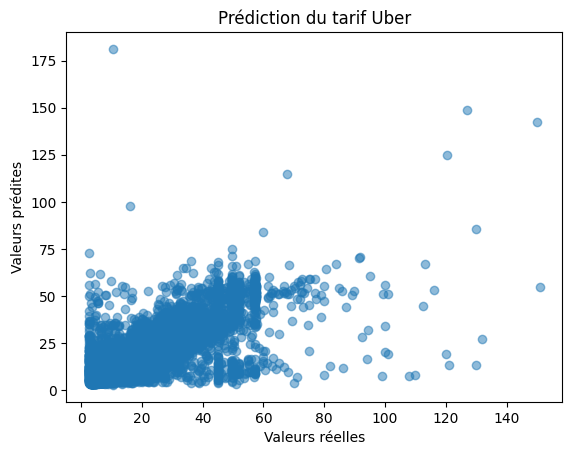

In [17]:
import matplotlib.pyplot as plt 
plt.scatter(y_test, y_pred_rf, alpha=0.5) 
plt.xlabel('Valeurs réelles') 
plt.ylabel('Valeurs prédites') 
plt.title('Prédiction du tarif Uber') 
plt.show() 

In [23]:
data = pd.read_csv('Titanic-Dataset.csv') 
print(data.head()) 
print(data.info()) 
print(data.isnull().sum())

   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C
2            3         1       3  ...   7.9250   NaN         S
3            4         1       1  ...  53.1000  C123         S
4            5         0       3  ...   8.0500   NaN         S

[5 rows x 12 columns]
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 

In [24]:
data = data[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']] 
data['Age'] = data['Age'].fillna(data['Age'].median()) 
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0]) 

In [25]:
from sklearn.preprocessing import LabelEncoder 
 
le = LabelEncoder() 
data['Sex'] = le.fit_transform(data['Sex']) 
data['Embarked'] = le.fit_transform(data['Embarked']) 

In [26]:
X = data.drop('Survived', axis=1) 
y = data['Survived'] 
 
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [27]:
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier 
 
log_model = LogisticRegression(max_iter=1000) 
rf_model = RandomForestClassifier(n_estimators=100, random_state=42) 
 
log_model.fit(X_train, y_train) 
rf_model.fit(X_train, y_train) 


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [28]:
from sklearn.metrics import accuracy_score, classification_report 
y_pred_log = log_model.predict(X_test) 
y_pred_rf = rf_model.predict(X_test) 
print('Accuracy (Logistic):', accuracy_score(y_test, y_pred_log)) 
print('Accuracy (Random Forest):', accuracy_score(y_test, y_pred_rf)) 
print(classification_report(y_test, y_pred_rf)) 

Accuracy (Logistic): 0.8100558659217877
Accuracy (Random Forest): 0.8212290502793296
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



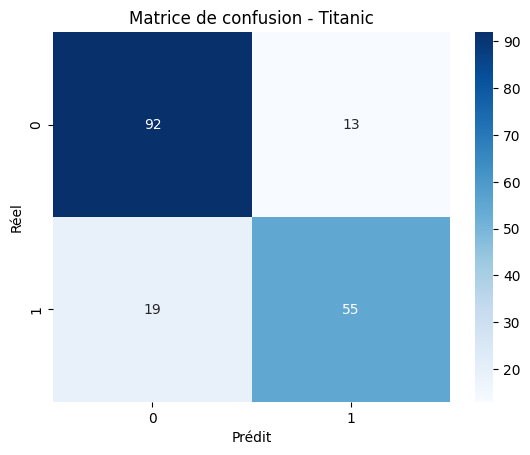

In [29]:
from sklearn.metrics import confusion_matrix 
import seaborn as sns 
import matplotlib.pyplot as plt 
cm = confusion_matrix(y_test, y_pred_rf) 
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues') 
plt.title('Matrice de confusion - Titanic') 
plt.xlabel('Prédit') 
plt.ylabel('Réel') 
plt.show() 